<a href="https://colab.research.google.com/github/elonsobrevilla06-byte/Youtube_Virality/blob/main/YoutubeViralOrNot_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

# 1.) Acquiring Data

In [ ]:
path = kagglehub.dataset_download("vedauv/what-makes-a-yt-video-go-viral-12000-vids")
df = pd.read_csv(f"{path}/viral_videos.csv")


100%|██████████| 330k/330k [00:00<00:00, 22.7MB/s]

Extracting files...


,video_id,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
0,vid_000001,Beauty,517,64,1,23,Wed,27,429,907474,970600,20610,4029,7208,1
1,vid_000002,Tech,495,47,1,23,Mon,10,222,1004641,104278,3907,554,554,0
2,vid_000003,Beauty,311,76,0,17,Mon,13,520,168170,18102,1021,77,122,0
3,vid_000004,Fitness,590,69,0,0,Mon,17,309,285593,52042,2587,142,964,0
4,vid_000005,Tech,380,58,1,19,Mon,0,101,1073326,908509,22993,1825,2611,1


In [ ]:
df.head()

,video_id,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
0,vid_000001,Beauty,517,64,1,23,Wed,27,429,907474,970600,20610,4029,7208,1
1,vid_000002,Tech,495,47,1,23,Mon,10,222,1004641,104278,3907,554,554,0
2,vid_000003,Beauty,311,76,0,17,Mon,13,520,168170,18102,1021,77,122,0
3,vid_000004,Fitness,590,69,0,0,Mon,17,309,285593,52042,2587,142,964,0
4,vid_000005,Tech,380,58,1,19,Mon,0,101,1073326,908509,22993,1825,2611,1


In [ ]:
df.describe()

,duration_sec,title_length,thumbnail_face,upload_hour,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,1.200000e+04,12000.000000
mean,631.619583,54.524000,0.400250,11.539417,14.586833,508.919417,1.009487e+06,7.677524e+05,3.750578e+04,4.739626e+03,9.503240e+03,0.200000
std,285.825411,14.950788,0.489969,6.914424,7.741422,287.212933,2.585562e+06,3.526908e+06,1.823115e+05,2.331387e+04,4.644499e+04,0.400017
min,30.000000,10.000000,0.000000,0.000000,0.000000,0.000000,3.636000e+03,1.390000e+02,6.000000e+00,0.000000e+00,1.000000e+00,0.000000
25%,408.000000,45.000000,0.000000,5.000000,9.000000,300.000000,1.585215e+05,6.123550e+04,2.790000e+03,3.167500e+02,6.417500e+02,0.000000
50%,614.000000,55.000000,0.000000,12.000000,14.000000,504.000000,3.813820e+05,1.852680e+05,8.751500e+03,1.018000e+03,2.050500e+03,0.000000
75%,822.000000,65.000000,1.000000,18.000000,20.000000,709.000000,9.298448e+05,5.569705e+05,2.657125e+04,3.207250e+03,6.527250e+03,0.000000
max,1960.000000,109.000000,1.000000,23.000000,44.000000,1618.000000,1.000000e+08,1.994657e+08,1.159287e+07,1.116186e+06,2.367174e+06,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   video_id            12000 non-null  object
 1   category            12000 non-null  object
 2   duration_sec        12000 non-null  int64 
 3   title_length        12000 non-null  int64 
 4   thumbnail_face      12000 non-null  int64 
 5   upload_hour         12000 non-null  int64 
 6   upload_day          12000 non-null  object
 7   tags_count          12000 non-null  int64 
 8   description_length  12000 non-null  int64 
 9   subscriber_count    12000 non-null  int64 
 10  views               12000 non-null  int64 
 11  likes               12000 non-null  int64 
 12  comments            12000 non-null  int64 
 13  shares              12000 non-null  int64 
 14  viral               12000 non-null  int64 
dtypes: int64(12), object(3)
memory usage: 1.4+ MB


In [ ]:
#getting all the object columns and int columns
object_columns = []
int_columns = []

for col in df.columns:
  if df[col].dtype == "object":
    object_columns.append(col)
  else:
    int_columns.append(col)

binary_cols = []
for c in int_columns:
  if df[c].isin([0,1]).all():
    binary_cols.append(c)





In [ ]:
print("Object Columns: ", object_columns)
print("int Columns: ", int_columns)
print("Binary Columns: ", binary_cols)

Object Columns:  ['video_id', 'category', 'upload_day']
int Columns:  ['duration_sec', 'title_length', 'thumbnail_face', 'upload_hour', 'tags_count', 'description_length', 'subscriber_count', 'views', 'likes', 'comments', 'shares', 'viral']
Binary Columns:  ['thumbnail_face', 'viral']


# 2.) Data Cleaning

In [ ]:
#Checking if theres any na value
df.isna().any(axis = None)
df.isna().sum()

,0
video_id,0
category,0
duration_sec,0
title_length,0
thumbnail_face,0
upload_hour,0
upload_day,0
tags_count,0
description_length,0
subscriber_count,0


In [ ]:
#Check for duplicate
print(df.duplicated().sum())
df[df.duplicated()]

#If theres any duplicate
#df = df.drop_duplicates()

0


,video_id,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral


In [ ]:
#Check Unique for every columns
for col in df.columns:
  print(f"\n--{col}--")
  print(df[col].unique())


--video_id--
['vid_000001' 'vid_000002' 'vid_000003' ... 'vid_011998' 'vid_011999'
 'vid_012000']

--category--
['Beauty' 'Tech' 'Fitness' 'Cooking' 'Education' 'Finance' 'Music'
 'Comedy' 'News' 'DIY' 'Travel' 'Science' 'Vlog' 'Gaming' 'Sports']

--duration_sec--
[ 517  495  311 ... 1380 1230 1552]

--title_length--
[ 64  47  76  69  58  31  70  41  15  66  44  50  55  56  36  67  51  71
  89  35  43  73  48  42  54  75  62  87  60  29  59  78  68  79  53  45
  63  30  26  28  20  14  52  65  22  34  49  61  74  57  85  77  33  81
  46  38  32  18  40  21  39  23  37  27  10  91  25  72  80  94  88  16
  82  24  84  92  19  90  83  93  99  13  17  96  86 104  95  98 108  11
  12 101 102 100 106 109 105  97 103]

--thumbnail_face--
[1 0]

--upload_hour--
[23 17  0 19 20 14 13 10 11  1 12 18 21  2 15  4  3  8  9  5 16  7 22  6]

--upload_day--
['Wed' 'Mon' 'Sat' 'Fri' 'Sun' 'Tue' 'Thu']

--tags_count--
[27 10 13 17  0 21 22 12 18 34  8  4 16 24 20 23 25 14 15 11 19  3  6  9
 26  5 28 3

# 3.) EDA

Index(['video_id', 'category', 'duration_sec', 'title_length',
       'thumbnail_face', 'upload_hour', 'upload_day', 'tags_count',
       'description_length', 'subscriber_count', 'views', 'likes', 'comments',
       'shares', 'viral'],
      dtype='object')


(12000, 15)

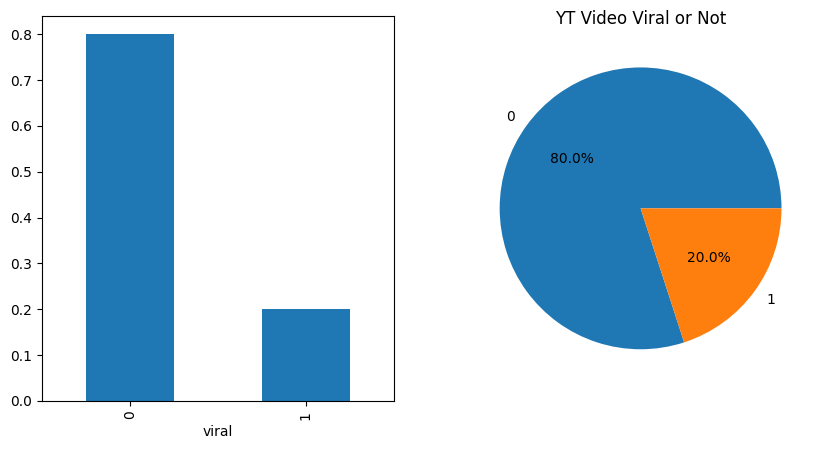

In [ ]:
print(df.columns)
fig, axes = plt.subplots(1,2, figsize = (10, 5))

df["viral"].value_counts(normalize = True).plot(kind = "bar", ax = axes[0])
df['viral'].value_counts(normalize = True).plot(
    kind = "pie",
    title = "YT Video Viral or Not",
    ylabel = '',
     autopct = '%1.1f%%',
     ax = axes[1],
)
df.shape


In [ ]:
df = df.drop(columns = "video_id")
df.columns

Index(['category', 'duration_sec', 'title_length', 'thumbnail_face',
       'upload_hour', 'upload_day', 'tags_count', 'description_length',
       'subscriber_count', 'views', 'likes', 'comments', 'shares', 'viral'],
      dtype='object')

array([[<Axes: title={'center': 'duration_sec'}>,
        <Axes: title={'center': 'title_length'}>,
        <Axes: title={'center': 'upload_hour'}>],
       [<Axes: title={'center': 'tags_count'}>,
        <Axes: title={'center': 'description_length'}>,
        <Axes: title={'center': 'subscriber_count'}>],
       [<Axes: title={'center': 'views'}>,
        <Axes: title={'center': 'likes'}>,
        <Axes: title={'center': 'comments'}>],
       [<Axes: title={'center': 'shares'}>, <Axes: >, <Axes: >]],
      dtype=object)

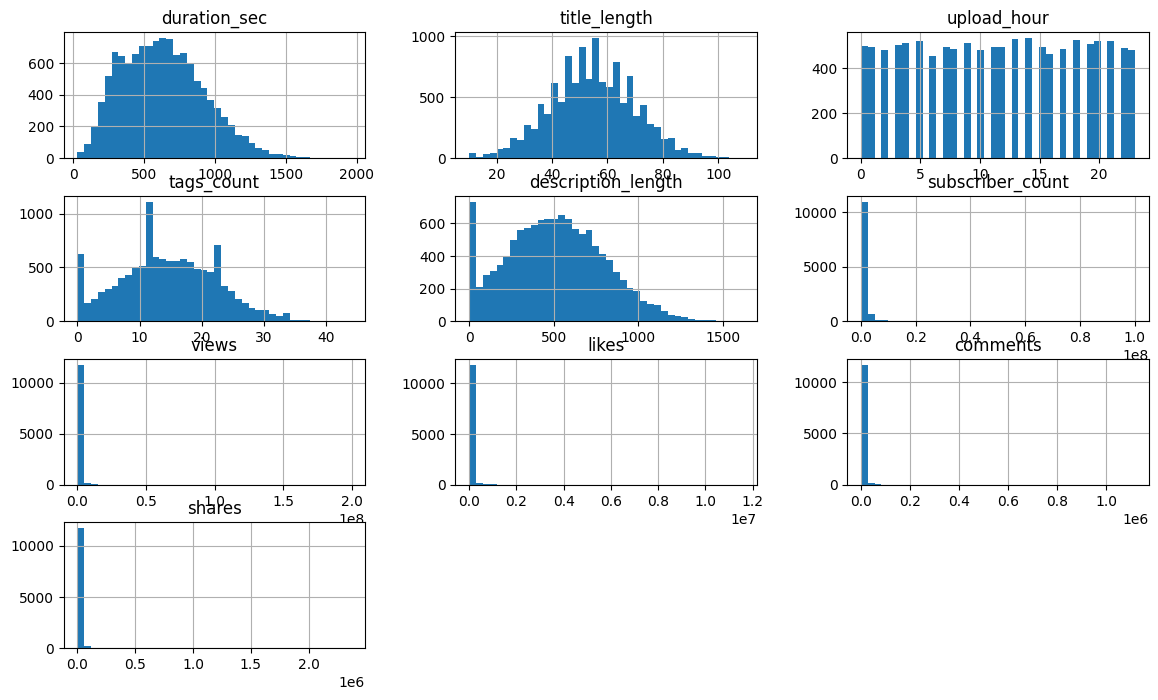

In [ ]:
df[num_cols].hist(bins = 40, figsize = (14,8))


In [ ]:
df.groupby("viral")[int_columns].mean()

,duration_sec,title_length,thumbnail_face,upload_hour,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
viral,,,,,,,,,,,,
0,653.963542,54.518958,0.386354,11.488854,14.474479,510.598854,4.743781e+05,1.875680e+05,9433.804167,1173.837083,2374.761250,0.0
1,542.243750,54.544167,0.455833,11.741667,15.036250,502.201667,3.149921e+06,3.088490e+06,149793.697500,19002.782083,38017.155833,1.0


In [ ]:
df.groupby("viral")["likes"].count()

,likes
viral,
0,9600
1,2400


In [ ]:
pd.crosstab(df["viral"], df["likes"]).T

viral,0,1
likes,,
6,1,0
19,1,0
22,1,0
28,1,0
30,1,0
...,...,...
4354977,0,1
5338524,0,1
5937206,0,1


In [ ]:
object_column = object_columns.drop("video_id")



KeyError: "['video_id'] not found in axis"

In [ ]:
df.groupby("viral")[object_columns].value_counts()

viral  category  upload_day
0      Vlog      Mon           131
       Travel    Sun           122
                 Tue           118
       Fitness   Thu           117
       DIY       Tue           113
                              ... 
1      Vlog      Fri             6
                 Thu             6
       Fitness   Sun             5
       Vlog      Mon             5
       Travel    Sat             2
Name: count, Length: 210, dtype: int64

In [ ]:
print(object_columns)

Index(['category', 'upload_day'], dtype='object')


In [ ]:
for c in ["category", "upload_day", "thumbnail_face", "upload_hour"]:
  print(df.groupby(c)["viral"].agg(rate ="mean", n ="count").round(2).sort_values("rate"), "\n")


           rate    n
category            
Vlog       0.07  821
Travel     0.08  807
Fitness    0.11  776
Science    0.11  808
Education  0.12  764
DIY        0.13  779
Finance    0.15  821
Cooking    0.17  794
Tech       0.19  824
News       0.19  825
Beauty     0.23  817
Gaming     0.24  807
Sports     0.28  806
Comedy     0.35  775
Music      0.57  776 

            rate     n
upload_day            
Sun         0.19  1746
Sat         0.19  1708
Tue         0.19  1627
Thu         0.20  1728
Fri         0.21  1697
Mon         0.21  1751
Wed         0.21  1743 

                rate     n
thumbnail_face            
0               0.18  7197
1               0.23  4803 

             rate    n
upload_hour           
2            0.16  482
1            0.17  496
3            0.17  503
15           0.18  496
20           0.18  522
13           0.19  530
5            0.19  521
14           0.19  535
16           0.19  462
11           0.20  497
10           0.20  482
6            0.20  454


In [ ]:
#Double Checking if the upload day is truly significant
pd.crosstab(df["upload_day"], df["viral"])

viral,0,1
upload_day,,
Fri,1346,351
Mon,1390,361
Sat,1387,321
Sun,1409,337
Thu,1376,352
Tue,1312,315
Wed,1380,363


In [ ]:
#Double checking if the upload day is truly significant
#use chi2_contingency if both is categorical
from scipy.stats import chi2_contingency
chi2, p, dof, exp =  chi2_contingency(pd.crosstab(df["upload_day"], df["viral"]))
print(p)

0.6355130961494175


In [ ]:
#testing all categorical value
for c in ["category", "thumbnail_face", "upload_hour"]:
  chi2, p, dof, exp = chi2_contingency(pd.crosstab(df[c], df["viral"]))
  print(f"Column {c}: {p:.8f}")



Column category: 0.00000000
Column thumbnail_face: 0.00000000
Column upload_hour: 0.31208904


In [ ]:
print(df.groupby("category")["thumbnail_face"].mean().round(3).sort_values())

#“For each category, compare the viral rate of videos without a face against the viral rate of videos with a face.”
print("\n" ,df.pivot_table(index="category", columns = "thumbnail_face", values = "viral", aggfunc="mean").round(3))

category
Tech         0.377
Finance      0.380
Gaming       0.384
Travel       0.385
Comedy       0.386
News         0.388
Fitness      0.389
Science      0.406
Beauty       0.408
Cooking      0.409
Vlog         0.413
Sports       0.413
Music        0.414
DIY          0.425
Education    0.429
Name: thumbnail_face, dtype: float64

 thumbnail_face      0      1
category                    
Beauty          0.207  0.273
Comedy          0.317  0.408
Cooking         0.151  0.200
DIY             0.118  0.157
Education       0.115  0.134
Finance         0.141  0.170
Fitness         0.095  0.146
Gaming          0.215  0.287
Music           0.536  0.623
News            0.164  0.219
Science         0.090  0.140
Sports          0.245  0.318
Tech            0.181  0.206
Travel          0.081  0.087
Vlog            0.079  0.062


In [ ]:
df.groupby("category")["subscriber_count"].median().sort_values()

,subscriber_count
category,
Vlog,198270.0
Travel,201805.0
Science,251703.0
Fitness,259620.5
Education,275011.0
DIY,285334.0
Finance,299502.0
Cooking,365019.0
Tech,398781.5
